# 피부 자극성 예측 — 모델 학습과 선택

> AI머신러닝 (2026-1) 기말 개인 프로젝트 · 2/2

1번 노트북이 만든 데이터셋으로 6종 모델을 비교하고 최종 모델을 고른 과정입니다.
전체 설명은 저장소 README를 참고하세요.


## ▶ 0. 환경 설정 및 데이터 로드

In [22]:
# -- 표준 라이브러리 --
import warnings
# -- 데이터 처리 --
import numpy as np
import pandas as pd
# -- 시각화 --
import matplotlib.pyplot as plt
import seaborn as sns
# -- 화학 정보(RDKit): 새 분자 예측 시 descriptor/fingerprint 계산 --
from rdkit import Chem
from rdkit.Chem import Descriptors, AllChem, rdFingerprintGenerator
# -- feature 선택 & 스케일링 --
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
# -- 교차검증 & 평가 지표 --
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, recall_score
# -- 분류 모델 6종 --
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
# -- 모델 저장 --
import joblib

warnings.filterwarnings('ignore')
np.random.seed(42)                           # 난수 시드 고정 : 실험할 때마다 같은 결과
plt.rcParams['axes.unicode_minus'] = False



### 0. template 1의 데이터 로드
df = pd.read_csv('final_dataset_descriptors.csv')
print('입력 데이터:', df.shape)
print('label 분포:', df['label'].value_counts().to_dict())
df.head()

입력 데이터: (266, 4485)
label 분포: {1: 156, 0: 110}


,Chemical_Name,SMILES,Cleaned_SMILES,Source,label,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,...,MACCS_157,MACCS_158,MACCS_159,MACCS_160,MACCS_161,MACCS_162,MACCS_163,MACCS_164,MACCS_165,MACCS_166
0,Propylene glycol,CC(O)CO,CC(O)CO,skin_irritation,0,8.111111,8.111111,0.138889,-0.560185,0.435835,...,1,0,1,1,0,0,0,1,0,0
1,Heptanal,CCCCCCC=O,CCCCCCC=O,skin_irritation,1,9.768009,9.768009,0.750000,0.750000,0.395123,...,0,0,0,1,0,0,0,1,0,0
2,Isopropyl myristate,CCCCCCCCCCCCCC(=O)OC(C)C,CCCCCCCCCCCCCC(=O)OC(C)C,skin_irritation,0,11.291588,11.291588,0.027971,-0.036181,0.319642,...,1,0,1,1,0,0,0,1,0,0
3,4-Methylthio benzaldehyde,CSC1=CC=C(C=O)C=C1,CSc1ccc(C=O)cc1,skin_irritation,0,10.199308,10.199308,0.734074,0.734074,0.477177,...,0,0,0,1,0,1,1,1,1,0
4,Heptyl butyrate,CCCCCCCOC(=O)CCC,CCCCCCCOC(=O)CCC,skin_irritation,0,10.909695,10.909695,0.043526,-0.043526,0.429221,...,1,0,1,1,0,0,0,1,0,0


### ▶ 1. 입력 데이터 준비

In [23]:
### 1. X / y 분리
meta_cols = ['Chemical_Name', 'SMILES', 'Cleaned_SMILES', 'Source', 'label']
# y : 정답(0/1)
y = df['label']  
# X : feature 후보
X = df.drop(columns=[c for c in meta_cols if c in df.columns])  
X = X.select_dtypes(include='number')    # 숫자형 feature만
print('초기 X:', X.shape)

# featue 정제
X = X.dropna(axis=1)                     # NaN 열 제거
print('NaN 제거 후:', X.shape)
X = X.loc[:, X.std() >= 0.01]            # 값이 거의 안 변하는(표준편차<0.01) 제거
print('저분산 제거 후:', X.shape)

# # X_scaled : X의 모든 열을 평균0·표준편차1로 맞춘 버전 (for LogReg·MLP·SVM)
scaler_all = StandardScaler()
X_scaled = pd.DataFrame(        
    scaler_all.fit_transform(X),
    columns=X.columns,
    index=X.index,
)



# 3개(20·60·160) 실험에서 MLP·SVM이 160에서도 계속 상승 → 포화점 확인 위해 320까지 확장
k_candidates = [20, 40, 80, 160, 240, 320]
# X에 실제로 있는 feature 수 보다 큰 K는 제거
k_candidates = [k for k in k_candidates if k <= X.shape[1]] 
print('실험할 k:', k_candidates)

초기 X: (266, 4480)
NaN 제거 후: (266, 4480)
저분산 제거 후: (266, 3437)
실험할 k: [20, 40, 80, 160, 240, 320]


#📌 `메타컬럼 + 저분산 feature 제거` 
- 메타 컬럼은 화합물 식별 정보이므로 정답 예측에 직접 넣으면 X
- 저분산 feature는 학습 신호가 부족함

→ 실패 가능성 줄이기

#📌 `k 후보군` 
- feature는 저분산 제거 후 3437개로 표본수(266)에 비해 압도적으로 많다. 그대로 쓰면 과적합 위험이
  크므로, SelectBest로 상위 k개만 선택해 feature 수를 줄인다.
- 후보 범위는 예비 실험으로 정했다. [20, 60, 160]로 learning curve를 확인한 결과, MLP·SVM의 성능이 **k=160에서도 꺾이지 않고 계속 상승했다.** 

→ 본 실험에서는 위쪽을 320까지 확장한다.

### ▶ 2. 평가 지표 정의

In [24]:
# specificity = label 0(비자극)에 대한 recall → make_scorer로 정의
spec_scorer = make_scorer(recall_score, pos_label=0)

# 평가 지표 6종
metric_scorers = {
    'accuracy': 'accuracy',                   # 전체 중 맞힌 비율 (불균형에 약함)
    'balanced_accuracy': 'balanced_accuracy', # 두 클래스 recall 평균 (불균형 보정)
    'f1': 'f1',                               # precision·recall 조화평균
    'mcc': 'matthews_corrcoef',               # 상관계수형 지표 (불균형에 강함)
    'sensitivity': 'recall',                  # 자극(1)을 자극이라 맞힌 비율 (recall)
    'specificity': spec_scorer,               # 위에서 만든 비자극(0) 기준 recall
}

def evaluate_model(model, X_input, y, cv=5):
    """ 모델 1개를 6개 지표로 각각 5-fold 교차 검증해서 {지표이름: 평균 점수} dict로 반환 """
    return {m: cross_val_score(model, X_input, y, cv=cv, scoring=s).mean()
            for m, s in metric_scorers.items()}

def add_result(results, model_name, k, param, model, X_input, y):
    """ 모델 1개의 결과(학습 정확도 + 6지표 CV)를 results 리스트에 한 줄(dict)로 추가 """
    train = model.fit(X_input, y).score(X_input, y)     # train : 학습 정확도(과적합 가늠용)
    scores = evaluate_model(model, X_input, y)
    row = {
        'model': model_name, 
        'k': k, 
        'param': param, 
        'train': round(train, 3)
    }
    for m, v in scores.items():
        row[m] = round(v, 3)
    # score_mean: 불균형에 강한 3지표 평균 → 최종 모델 '선택 기준'
    row['score_mean'] = round(np.mean([scores['balanced_accuracy'], scores['f1'], scores['mcc']]), 3)
    results.append(row)

print('평가 지표:', list(metric_scorers.keys()))


평가 지표: ['accuracy', 'balanced_accuracy', 'f1', 'mcc', 'sensitivity', 'specificity']


#📌 `accuracy`만 쓰지 않는 이유 
- label 불균형이 있으면 accuracy는 모델을 과대평가할 수 있다.
- 최종 선택 : balanced_accuracy + f1 + mcc의 평균 = 'score_mean'

→ **실패**(자극 물질 놓침 / 비자극 물질 잘못 경고) **고려**

### ▶ 3. 모델 학습

In [25]:
### 3. 선형/거리 기반 모델: LogReg, MLP, SVM
results = []

for k in k_candidates:
    print(f'k={k} 시작...') 
    
    # 스케일링된 데이터에서 점수 상위 k개 feature 선택
    selector = SelectKBest(f_classif, k=k)
    selector.fit(X_scaled, y)
    # 선택된 feature 이름
    cols = X_scaled.columns[selector.get_support()]
    # 그 feature만 추린 학습 행렬
    X_sel = X_scaled[cols]                         
    
    # LogReg : 가장 단순한 기준선 (max_iter는 수렴 위해 크게)
    p = {'max_iter': 5000}
    add_result(results, 'LogReg', k, p, LogisticRegression(**p), X_sel, y)

    # MLP: hidden node 수(h) + activation
    for h in [20, 50, 100]:
        for activation in ['relu', 'tanh']:
            p = {'hidden_layer_sizes': (h,), 'activation': activation, 'max_iter': 5000, 'random_state': 42}
            add_result(results, 'MLP', k, p, MLPClassifier(**p), X_sel, y)


    # SVM: 규제 강도 C + kernel grid search
    for c_val in [0.1, 1, 10]:
        for kernel in ['linear', 'rbf']:
            p = {'C': c_val, 'kernel': kernel, 'random_state': 42}
            add_result(results, 'SVM', k, p, SVC(**p), X_sel, y)


# 중간 결과 확인
pd.DataFrame(results).sort_values('score_mean', ascending=False).head(10)

k=20 시작...
k=40 시작...
k=80 시작...
k=160 시작...
k=240 시작...
k=320 시작...


,model,k,param,train,accuracy,balanced_accuracy,f1,mcc,sensitivity,specificity,score_mean
70,MLP,320,"{'hidden_layer_sizes': (100,), 'activation': '...",1.000,0.797,0.791,0.829,0.584,0.827,0.755,0.735
66,MLP,320,"{'hidden_layer_sizes': (20,), 'activation': 'r...",1.000,0.774,0.762,0.814,0.537,0.834,0.691,0.704
68,MLP,320,"{'hidden_layer_sizes': (50,), 'activation': 'r...",1.000,0.771,0.762,0.807,0.530,0.815,0.709,0.699
40,MLP,160,"{'hidden_layer_sizes': (20,), 'activation': 'r...",0.989,0.763,0.758,0.795,0.525,0.789,0.727,0.693
55,MLP,240,"{'hidden_layer_sizes': (50,), 'activation': 'r...",1.000,0.763,0.758,0.796,0.519,0.789,0.727,0.691
77,SVM,320,"{'C': 10, 'kernel': 'rbf', 'random_state': 42}",0.981,0.763,0.751,0.803,0.512,0.821,0.682,0.689
43,MLP,160,"{'hidden_layer_sizes': (50,), 'activation': 't...",1.000,0.756,0.746,0.790,0.505,0.802,0.691,0.681
51,SVM,160,"{'C': 10, 'kernel': 'rbf', 'random_state': 42}",0.955,0.756,0.740,0.798,0.501,0.834,0.645,0.680
49,SVM,160,"{'C': 1, 'kernel': 'rbf', 'random_state': 42}",0.887,0.756,0.734,0.805,0.500,0.860,0.609,0.680
57,MLP,240,"{'hidden_layer_sizes': (100,), 'activation': '...",1.000,0.752,0.740,0.792,0.489,0.808,0.673,0.674


#📌 `선형/거리 기반 모델`을 먼저 비교한 이유 
- 세 모델은 값의 크기(scale)에 민감하므로 스케일링된 X_scaled를 쓴다.
- LogReg : 단순 기준선 / MLP : 비선형 관계 학습(hidden node가 크면 과적합) / 
  SVM : 작은 데이터에 강하나 C·kernel에 민감

→ feature 수 k와 하이퍼파라미터를 함께 바꿔 실패 조합까지 result에 기록한다.

In [26]:
### 3. 트리/앙상블 모델: DT, RF, XGB 
for k in k_candidates:
    print(f'k={k} 시작...') 
    
    # 원본 X에서 feature 선
    selector = SelectKBest(f_classif, k=k)
    selector.fit(X, y)
    cols = X.columns[selector.get_support()]
    X_sel = X[cols]

    # Decision Tree: depth + min_samples_split
    for d in [3, 5, None]:                            # None = 깊이 제한 없음
        for s in [2, 4]:
            p = {'max_depth': d, 'min_samples_split': s, 'random_state': 0}
            add_result(results, 'DT', k, p, DecisionTreeClassifier(**p), X_sel, y)

    # Random Forest: 트리 수(n) + depth 
    for n in [100, 200]:
        for d in [3, 5, None]:
            p = {'n_estimators': n, 'max_depth': d, 'random_state': 0}
            add_result(results, 'RF', k, p, RandomForestClassifier(**p), X_sel, y)

    # XGBoost: 트리 수·depth·learning rate 
    for n in [100, 200]:
        for d in [3, 5]:
            for lr in [0.05, 0.1]:
                p = {'n_estimators': n, 'max_depth': d, 'learning_rate': lr,
                     'random_state': 0, 'eval_metric': 'logloss'}
                add_result(results, 'XGB', k, p, XGBClassifier(**p), X_sel, y)



# 선형+트리 전체 결과를 표로 → 종합점수 상위 10개
results_df = pd.DataFrame(results)
results_df.sort_values('score_mean', ascending=False).head(10)

k=20 시작...
k=40 시작...
k=80 시작...
k=160 시작...
k=240 시작...
k=320 시작...


,model,k,param,train,accuracy,balanced_accuracy,f1,mcc,sensitivity,specificity,score_mean
70,MLP,320,"{'hidden_layer_sizes': (100,), 'activation': '...",1.000,0.797,0.791,0.829,0.584,0.827,0.755,0.735
66,MLP,320,"{'hidden_layer_sizes': (20,), 'activation': 'r...",1.000,0.774,0.762,0.814,0.537,0.834,0.691,0.704
68,MLP,320,"{'hidden_layer_sizes': (50,), 'activation': 'r...",1.000,0.771,0.762,0.807,0.530,0.815,0.709,0.699
40,MLP,160,"{'hidden_layer_sizes': (20,), 'activation': 'r...",0.989,0.763,0.758,0.795,0.525,0.789,0.727,0.693
55,MLP,240,"{'hidden_layer_sizes': (50,), 'activation': 'r...",1.000,0.763,0.758,0.796,0.519,0.789,0.727,0.691
77,SVM,320,"{'C': 10, 'kernel': 'rbf', 'random_state': 42}",0.981,0.763,0.751,0.803,0.512,0.821,0.682,0.689
43,MLP,160,"{'hidden_layer_sizes': (50,), 'activation': 't...",1.000,0.756,0.746,0.790,0.505,0.802,0.691,0.681
51,SVM,160,"{'C': 10, 'kernel': 'rbf', 'random_state': 42}",0.955,0.756,0.740,0.798,0.501,0.834,0.645,0.680
49,SVM,160,"{'C': 1, 'kernel': 'rbf', 'random_state': 42}",0.887,0.756,0.734,0.805,0.500,0.860,0.609,0.680
38,SVM,80,"{'C': 10, 'kernel': 'rbf', 'random_state': 42}",0.940,0.752,0.738,0.793,0.491,0.822,0.655,0.674


#📌 `트리/앙상블 모델` 
- 세 모델은 스케일링이 필요 없어 원본 X를 쓴다.
- DT : 해석이 쉬우나 깊으면 과적합 / RF : 여러 트리를 평균내 안정화 / XGB : 오답을 순차 보완
- 같은 k에서도 depth·tree 수·learning rate에 따라 성능이 달라지므로 grid로 비교한다.

→ 결과는 앞 result에 이어서 기록한다.

### ▶ 4. 결과 정리 & 저장

In [17]:
# 전체 실험 결과를 score_mean 높은 순으로 정렬 → csv 저장 (experiment_result)
results_df = results_df.sort_values('score_mean', ascending=False).reset_index(drop=True)
results_df.to_csv('experiment_results.csv', index=False)

print('=== 전체 Top 10 (score_mean 기준) ===')
print(results_df.head(10).to_string(index=False))

# 모델별 가장 좋은 조합 → csv 저장 (experiment_best)
best_each = (results_df.sort_values('score_mean', ascending=False)
                       .groupby('model')
                       .head(1)
                       .sort_values('model'))
best_each.to_csv('experiment_best.csv', index=False)

print('\n=== 모델별 베스트 ===')
print(best_each.to_string(index=False))
print('\n저장 완료: experiment_results.csv, experiment_best.csv')

=== 전체 Top 10 (score_mean 기준) ===
model   k                                                                                      param  train  accuracy  balanced_accuracy    f1   mcc  sensitivity  specificity  score_mean
  MLP 320 {'hidden_layer_sizes': (100,), 'activation': 'relu', 'max_iter': 5000, 'random_state': 42}  1.000     0.797              0.791 0.829 0.584        0.827        0.755       0.735
  MLP 320  {'hidden_layer_sizes': (20,), 'activation': 'relu', 'max_iter': 5000, 'random_state': 42}  1.000     0.774              0.762 0.814 0.537        0.834        0.691       0.704
  MLP 320  {'hidden_layer_sizes': (50,), 'activation': 'relu', 'max_iter': 5000, 'random_state': 42}  1.000     0.771              0.762 0.807 0.530        0.815        0.709       0.699
  MLP 160  {'hidden_layer_sizes': (20,), 'activation': 'relu', 'max_iter': 5000, 'random_state': 42}  0.989     0.763              0.758 0.795 0.525        0.789        0.727       0.693
  MLP 240  {'hidden_layer_sizes

### ▶ 5. 시각화

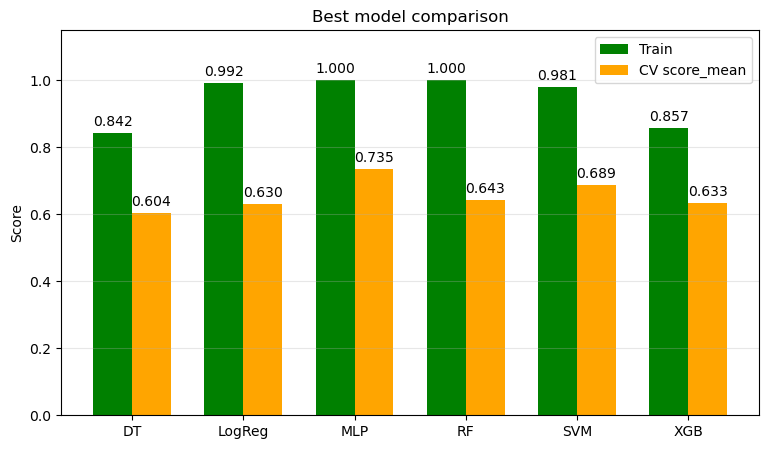

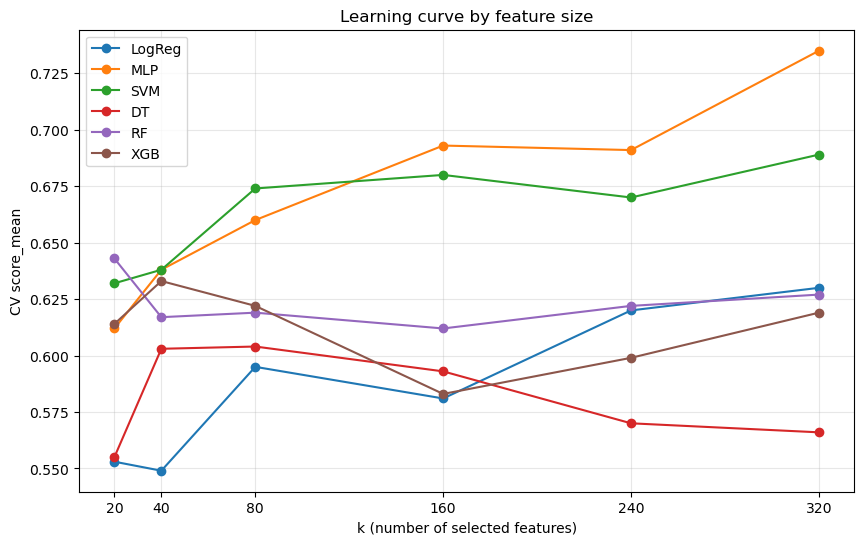

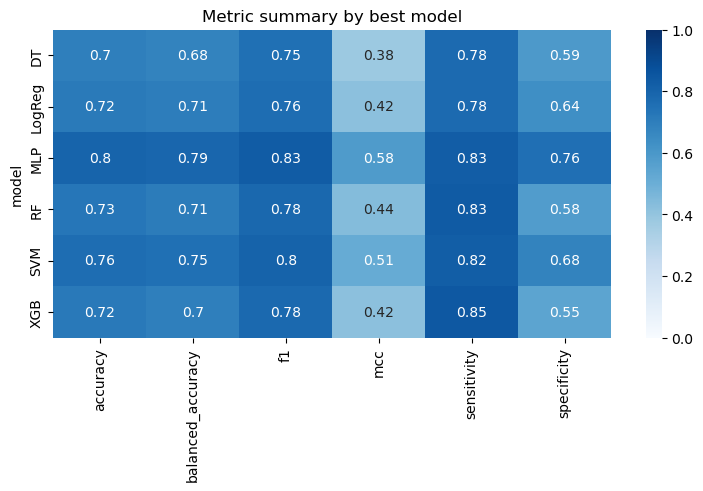

In [21]:
# 5-1. 모델별 베스트: train vs CV 종합점수 (격차가 크면 과적합 신호)
models = best_each['model'].tolist()
x = np.arange(len(models))
width = 0.35
fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.bar(x - width/2, best_each['train'],      width, label='Train',         color='green')
b2 = ax.bar(x + width/2, best_each['score_mean'], width, label='CV score_mean', color='orange')
ax.set_ylabel('Score'); ax.set_title('Best model comparison')
ax.set_xticks(x); ax.set_xticklabels(models); ax.set_ylim(0, 1.15); ax.legend()
for rects in [b1, b2]:                       # 막대 위에 숫자 표시
    for r in rects:
        ax.annotate(f'{r.get_height():.3f}', xy=(r.get_x()+r.get_width()/2, r.get_height()),
                    xytext=(0, 3), textcoords='offset points', ha='center', va='bottom')
plt.grid(axis='y', alpha=0.3); plt.show()



# 5-2. k별 learning curve: feature 수가 성능에 주는 영향 (모델마다 k별 best 1개)
plt.figure(figsize=(10, 6))
for model_name in ['LogReg', 'MLP', 'SVM', 'DT', 'RF', 'XGB']:
    df_m = results_df[results_df['model'] == model_name]
    df_m_best = df_m.sort_values('score_mean', ascending=False).groupby('k').head(1).sort_values('k')
    plt.plot(df_m_best['k'], df_m_best['score_mean'], marker='o', label=model_name)
plt.xlabel('k (number of selected features)'); plt.ylabel('CV score_mean')
plt.title('Learning curve by feature size'); plt.xticks(k_candidates); plt.legend(); plt.grid(alpha=0.3)
plt.show()



# 5-3. metric heatmap: 모델별 베스트의 6개 지표를 한눈에 (accuracy로 놓치는 균형 확인)
metric_cols = ['accuracy', 'balanced_accuracy', 'f1', 'mcc', 'sensitivity', 'specificity']
heat = best_each.set_index('model')[metric_cols]
plt.figure(figsize=(9, 4))
sns.heatmap(heat, annot=True, cmap='Blues', vmin=0, vmax=1)
plt.title('Metric summary by best model'); plt.show()

#📌 `시각화 3종` 설명

1. `Best model comparison (bar)`
- **과적합 여부** : 두 막대의 격차가 클수록 과적합 경향이 크다.
- **MLP**가 CV 0.735로 성능이 가장 높다. (격차는 존재하나, DT·XGB는 CV 성능 자체가 0.60~0.63으로 train·CV가 함께 저조)

2. `Learning curve`
- feature 수 k가 성능에 주는 영향
- **MLP·SVM**은 k가 커질수록 뚜렷이 상승해 많은 feature를 잘 활용한다.

3. `Metric summary (heatmap)`
- 모델별 베스트의 6개 지표 비교
- accuracy만 보면 비슷해 보이지만, **MLP**는 mcc(0.58)·specificity(0.76)에서 뚜렷이 앞선다.
- 모든 모델이 sensitivity는 높고 specificity는 낮다. 이는 자극은 잘 잡지만 비자극을 자극으로 경고하는 경향으로, 1번 template `4.시각화`에서 지적했던 `양성 치우침`과 연결된다.

<br>

→ `위와 같은 이유로 두 지표(specificity + MCC)에서 가장 균형 잡힌 MLP를 최종 모델로 선택한다.`

### ▶ 6. 최종 모델 저장 + 새 분자 예측

In [19]:
### 6. 최종 모델 저장

# 종합점수 1등 조합을 최종 모델로 선택
best = results_df.iloc[0]
print('최종 선택 조합:')
print(best.to_string())

best_model_name = best['model']
best_k = int(best['k'])
best_param = best['param']

# param(dict)을 생성자에 풀어 넣어 모델 복원
CONSTRUCTORS = {
    'LogReg': LogisticRegression, 'MLP': MLPClassifier, 'SVM': SVC,
    'DT': DecisionTreeClassifier, 'RF': RandomForestClassifier, 'XGB': XGBClassifier,
}
def make_model(name, param):
    return CONSTRUCTORS[name](**param)

# 최종 모델의 전처리: 선형 계열이면 스케일링, 트리 계열이면 원본 
if best_model_name in ['LogReg', 'MLP', 'SVM']:
    selector_final = SelectKBest(f_classif, k=best_k); selector_final.fit(X_scaled, y)
    final_cols = X_scaled.columns[selector_final.get_support()]
    scaler_final = StandardScaler()
    X_final = scaler_final.fit_transform(X[final_cols])
else:
    selector_final = SelectKBest(f_classif, k=best_k); selector_final.fit(X, y)
    final_cols = X.columns[selector_final.get_support()]
    scaler_final = None                       # 트리는 스케일러 없음
    X_final = X[final_cols]

# 최종 모델을 전체 데이터로 학습
model_best = make_model(best_model_name, best_param)
model_best.fit(X_final, y)

# 저장 (모델 + feature 목록 + scaler)
saved = {'features': list(final_cols), 'scaler': scaler_final,
         'model': model_best, 'best_row': best.to_dict()}
joblib.dump(saved, 'model_best.joblib')
print('저장 완료: model_best.joblib')
print('최종 모델 train accuracy:', round(model_best.score(X_final, y), 3))

최종 선택 조합:
model                                                              MLP
k                                                                  320
param                {'hidden_layer_sizes': (100,), 'activation': '...
train                                                              1.0
accuracy                                                         0.797
balanced_accuracy                                                0.791
f1                                                               0.829
mcc                                                              0.584
sensitivity                                                      0.827
specificity                                                      0.755
score_mean                                                       0.735
저장 완료: model_best.joblib
최종 모델 train accuracy: 1.0


#📌 `train accuracy : 1.0`
- `5. 시각화`에서 설명했듯 과적합 경향은 존재하나,
- ① CV 성능이 0.73~0.80으로 충분히 쓸 만하고
- ② 이 격차는 표본 수(266) 대비 feature가 많은 데이터 특성(p≫n)에서 비롯된 구조적 한계로 모든 모델에 공통으로 나타난다.

→ 데이터 규모의 한계가 반영된 결과로 해석

In [20]:
### 6. 새 분자 예측
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
rdkit_gen  = rdFingerprintGenerator.GetRDKitFPGenerator(fpSize=2048)

def calc_feature_row(smi):
    """SMILES 1개 → descriptor + 3 fingerprint를 한 줄(dict)로 (template 1과 동일 방식)"""
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    row = Descriptors.CalcMolDescriptors(mol)
    for i, b in enumerate(morgan_gen.GetFingerprint(mol)):
        row[f'Morgan_{i}'] = int(b)
    for i, b in enumerate(rdkit_gen.GetFingerprint(mol)):
        row[f'RDKitFP_{i}'] = int(b)
    for i, b in enumerate(AllChem.GetMACCSKeysFingerprint(mol)):
        row[f'MACCS_{i}'] = int(b)
    return row

# 예측해볼 새 분자 3개
new_mols = {
    'Aspirin':      'CC(=O)OC1=CC=CC=C1C(=O)O',
    'Caffeine':     'Cn1cnc2c1c(=O)n(C)c(=O)n2C',
    'Benzaldehyde': 'O=CC1=CC=CC=C1',
}

# 각 분자의 feature row 생성 → 표로
rows = []
for name, smi in new_mols.items():
    row = calc_feature_row(smi)
    row['name'] = name
    rows.append(row)
new_X = pd.DataFrame(rows).set_index('name')

# 최종 모델이 쓰는 feature만 같은 순서로 맞추고, 없는 값은 0으로 채움
new_X = new_X.reindex(columns=final_cols).fillna(0)

# 선형 계열이면 저장된 scaler로 변환, 트리 계열이면 그대로
new_X_input = scaler_final.transform(new_X) if scaler_final is not None else new_X

# 예측
new_pred = model_best.predict(new_X_input)
pred_df = pd.DataFrame({'SMILES': list(new_mols.values()), 'pred_label': new_pred},
                       index=list(new_mols.keys()))
pred_df

,SMILES,pred_label
Aspirin,CC(=O)OC1=CC=CC=C1C(=O)O,0
Caffeine,Cn1cnc2c1c(=O)n(C)c(=O)n2C,0
Benzaldehyde,O=CC1=CC=CC=C1,0


#📌 `모델과 함께 feature+scaler를 저장한 이유` 
- 모델만 저장하면 새 분자를 예측할 때 어떤 feature를 어떤 순서로 넣을지 잃어버릴 수 있다.

→ 새 분자도 T1과 똑같이 descriptor·fingerprint를 계산한다. 그다음 모델이 학습에 쓴 feature들만, 같은 순서로 골라 넣는다.